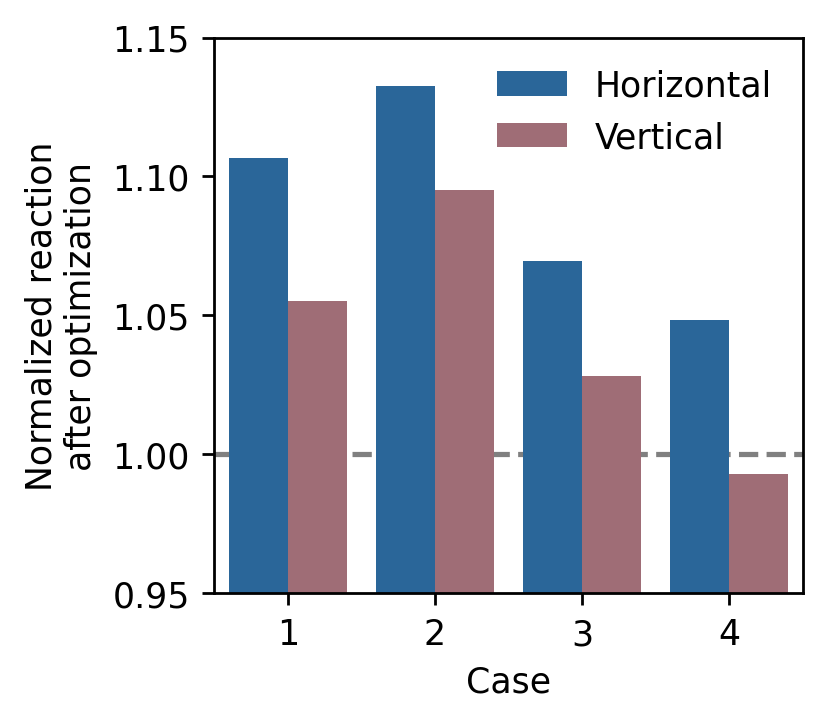

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

thres_paths = {
    4: "../../outputs/semisphere-2026-04-13-20-32-32-case4-radius003/records_opt.csv",
    3: "../../outputs/semisphere-2026-04-13-20-32-25-case3-radius003/records_opt.csv",
    2: "../../outputs/semisphere-2026-04-13-20-32-18-case2-radius003/records_opt.csv",
    1: "../../outputs/semisphere-2026-04-13-20-32-11-case1-radius003/records_opt.csv",
}

dfs = {
    key: pd.read_csv(val) for key, val in thres_paths.items()
}

dfs_processed = {
    key: pd.DataFrame({"thres": [key, key], "type": ["Horizontal", "Vertical"], "value": [val["bottom_x"].values[-1]/val["bottom_x"].values[0], val["bottom_y"].values[-1]/val["bottom_y"].values[0]], "abs_increase": [val["bottom_x"].values[-1]-val["bottom_x"].values[0], val["bottom_y"].values[-1]-val["bottom_y"].values[0]]}) for key, val in dfs.items()
}

df_thres = pd.concat(dfs_processed.values())

no_thres_paths = {
    4: "../../outputs/semisphere-2026-04-13-21-12-37-case4-radius001/records_opt.csv",
    3: "../../outputs/semisphere-2026-04-13-21-12-31-case3-radius001/records_opt.csv",
    2: "../../outputs/semisphere-2026-04-13-21-12-19-case2-radius001/records_opt.csv",
    1: "../../outputs/semisphere-2026-04-13-21-12-24-case1-radius001/records_opt.csv",
}

dfs = {
    key: pd.read_csv(val) for key, val in no_thres_paths.items()
}

dfs_processed = {
    key: pd.DataFrame({"thres": [key, key], "type": ["Horizontal", "Vertical"], "value": [val["bottom_x"].values[-1]/val["bottom_x"].values[0], val["bottom_y"].values[-1]/val["bottom_y"].values[0]], "abs_increase": [val["bottom_x"].values[-1]-val["bottom_x"].values[0], val["bottom_y"].values[-1]-val["bottom_y"].values[0]]}) for key, val in dfs.items()
}

df_no_thres = pd.concat(dfs_processed.values())

# df_thres["with_grad_penalty"] = "Yes"
# df_no_thres["with_grad_penalty"] = "No"

import seaborn as sns

plt.figure(figsize=(3.5,3.0), dpi=250)
ax = plt.subplot(111)
sns.barplot(data=df_thres, x="thres", y="value", hue="type", palette=["#1768AC", "#A76571"], ax=ax)
xlim = ax.get_xlim()
ax.hlines(1.0, *ax.get_xlim(), ls="--", colors="grey", zorder=0)
ax.set_xlim(xlim)
ax.set_ylim([0.95, 1.15])
# ax.set_yticks([0.95, 1.0, 1.05, 1.1])
handles, labels = ax.get_legend_handles_labels()
ax.get_legend().remove()
ax.legend(handles=handles, labels=labels, title=False, frameon=False)
ax.set_xlabel(r"Case")
ax.set_ylabel("Normalized reaction\nafter optimization")

# ax = plt.subplot(122)
# sns.barplot(data=df_thres, x="thres", y="abs_increase", hue="type", palette=["#1768AC", "#A76571"], ax=ax)
# handles, labels = ax.get_legend_handles_labels()
# ax.get_legend().remove()
# ax.legend(handles=handles, labels=labels, title=False, frameon=False)
# ax.set_xlabel(r"Case")
# ax.set_ylabel("Increase of reactions (N)\nafter optimizing $c$")
# ax.ticklabel_format(axis='y', style='sci', scilimits=(0,0), useMathText=True)
# ax.set_ylim([0, 2e-3])

plt.tight_layout()
plt.savefig("semisphere_reaction_diff.pdf", bbox_inches="tight")
plt.show()
plt.close()